# Luxembourg LOD2 屋顶正式查询与非评分评价

本 notebook 读取 `01_luxembourg_metrics_and_retrieval.ipynb` 已生成的指标文件，不重复读取或计算原始 CityGML。目标是在开发查询之外固定 20 个正式查询，用冻结的 M1、屋顶指标和 `lambda=0.35` 运行成对检索，并比较建筑级屋顶分布。Luxembourg 仍是开发城市；这些结果用于固定流程，不替代后续多城市验证。

## 1. 环境与固定参数

参数从第一次运行保存的配置中读取。代码会检查主权重、候选池和 Top-5，防止不经意地改变开发阶段已经冻结的规则。数据库只写入 `exp_lod2_roof_lu`。

In [2]:
from __future__ import annotations

import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
from IPython.display import display

HERE = Path.cwd().resolve()
if not (HERE / 'outputs').is_dir():
    HERE = (HERE / 'casebase' / 'lod2_roof_retrieval_experiment').resolve()
if not (HERE / 'outputs').is_dir():
    raise FileNotFoundError('请先运行 01 notebook，并从实验目录或项目根目录启动本 notebook')
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

import database as db
from evaluation import (
    evaluate_roof_distributions,
    select_formal_queries,
    summarize_formal_evaluation,
)
from retrieval import RobustFeatureScaler, retrieve_for_query

EXPERIMENT_SCHEMA = 'exp_lod2_roof_lu'
WRITE_EXPERIMENT_SCHEMA = True
SELECTION_SEED = 20260908
FORMAL_QUERY_COUNT = 20
REGULAR_QUERY_COUNT = 16
PRIMARY_LAMBDA = 0.35
OUTPUT_DIR = HERE / 'outputs' / 'formal_luxembourg'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
db.assert_experiment_relation(db.FORMAL_QUERY_TABLE)
db.assert_experiment_relation(db.FORMAL_EVALUATION_TABLE)

'exp_lod2_roof_lu.formal_evaluation_results'

## 2. 读取 `01` 的输出

只保留通过最低可用性门槛的街区和建筑。配置中的 11 项 M1 指标、3 项屋顶指标及缩放参数原样复用。

In [3]:
required_files = {
    'blocks': HERE / 'outputs' / 'block_metrics.parquet',
    'buildings': HERE / 'outputs' / 'building_metrics.parquet',
    'development_queries': HERE / 'outputs' / 'development_queries.csv',
    'config': HERE / 'outputs' / 'experiment_config.json',
}
missing_files = [str(path) for path in required_files.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError('缺少 01 notebook 输出：' + ', '.join(missing_files))

blocks = pd.read_parquet(required_files['blocks'])
buildings = pd.read_parquet(required_files['buildings'])
development_queries = pd.read_csv(required_files['development_queries'])
config = json.loads(required_files['config'].read_text(encoding='utf-8'))
usable_blocks = blocks[blocks['is_usable'].astype(bool)].copy()
usable_buildings = buildings[buildings['is_usable'].astype(bool)].copy()

M1_FEATURES = config['m1_features_after_pruning']
ROOF_FEATURES = config['roof_features']
POOL_SIZE = int(config['pool_size'])
TOP_K = int(config['top_k'])
assert PRIMARY_LAMBDA in config['lambda_values']
assert POOL_SIZE == 50 and TOP_K == 5
assert len(M1_FEATURES) == 11 and len(ROOF_FEATURES) == 3
display(pd.DataFrame({
    '对象': ['可用街区', '可用建筑', '开发查询'],
    '数量': [len(usable_blocks), len(usable_buildings), len(development_queries)],
}))

,对象,数量
0,可用街区,500
1,可用建筑,20568
2,开发查询,5


## 3. 固定 20 个正式查询

5 个开发查询全部排除。正式集合包括按平均屋顶坡度四分位抽取的 16 个常规查询，以及近似平屋顶、陡屋顶、高起伏和高离散 4 个边界案例。边界案例用于解释适用条件，不作为随机总体的代表。

In [4]:
formal_queries = select_formal_queries(
    usable_blocks,
    development_ids=development_queries['block_id'].astype(str),
    seed=SELECTION_SEED,
    regular_count=REGULAR_QUERY_COUNT,
)
formal_queries['selection_seed'] = SELECTION_SEED
assert len(formal_queries) == FORMAL_QUERY_COUNT
assert formal_queries['block_id'].nunique() == FORMAL_QUERY_COUNT
assert set(formal_queries['block_id']).isdisjoint(set(development_queries['block_id'].astype(str)))
display(formal_queries.groupby(['query_role', 'stratum']).size().rename('数量').to_frame())
display(formal_queries)

数量
query_role stratum            
boundary   high_dispersion   1
           high_relief       1
           near_flat         1
           steep             1
regular    slope_q1          4
           slope_q2          4
           slope_q3          4
           slope_q4          4

,block_id,query_role,stratum,roof_mean_slope,roof_relief_ratio_median,building_roof_slope_sd,selection_seed
0,LU_LU_000303,boundary,near_flat,0.000000,0.000000,0.000000,20260908
1,LU_LU_000512,boundary,steep,46.114183,0.925494,0.000000,20260908
2,LU_LU_000336,boundary,high_relief,26.063385,0.866721,0.000000,20260908
3,LU_LU_000611,boundary,high_dispersion,38.098848,0.581605,21.528247,20260908
4,LU_LU_000313,regular,slope_q1,4.971050,0.834302,6.583421,20260908
5,LU_LU_000529,regular,slope_q1,0.781434,0.445769,0.993542,20260908
6,LU_LU_000598,regular,slope_q1,0.001218,0.230841,0.001308,20260908
7,LU_LU_000682,regular,slope_q1,0.000000,0.000000,0.000000,20260908
8,LU_LU_000266,regular,slope_q2,23.146858,0.625044,16.033702,20260908
9,LU_LU_000404,regular,slope_q2,18.000938,0.492771,14.496586,20260908


## 4. 用冻结参数运行 M1/M2

缩放中位数和四分位距直接取自开发阶段配置，而不是在正式查询后重新拟合。每个查询由 M1 返回 5 个结果、M2 返回 5 个结果，共应得到 200 行。

In [5]:
general_scaler = RobustFeatureScaler(
    tuple(M1_FEATURES),
    pd.Series(config['general_scaler_medians']).reindex(M1_FEATURES),
    pd.Series(config['general_scaler_iqrs']).reindex(M1_FEATURES),
)
roof_scaler = RobustFeatureScaler(
    tuple(ROOF_FEATURES),
    pd.Series(config['roof_scaler_medians']).reindex(ROOF_FEATURES),
    pd.Series(config['roof_scaler_iqrs']).reindex(ROOF_FEATURES),
)
retrieval = pd.concat(
    [
        retrieve_for_query(
            usable_blocks,
            query_id=query_id,
            general_features=M1_FEATURES,
            roof_features=ROOF_FEATURES,
            pool_size=POOL_SIZE,
            top_k=TOP_K,
            lambda_values=[PRIMARY_LAMBDA],
            general_scaler=general_scaler,
            roof_scaler=roof_scaler,
        )
        for query_id in formal_queries['block_id']
    ],
    ignore_index=True,
)
query_metadata = formal_queries[['block_id', 'query_role', 'stratum']].rename(columns={'block_id': 'query_id'})
retrieval = retrieval.merge(query_metadata, on='query_id', how='left', validate='many_to_one')
assert len(retrieval) == FORMAL_QUERY_COUNT * TOP_K * 2
display(retrieval.groupby(['query_role', 'method', 'lambda_value']).size().rename('结果数').to_frame())

结果数
query_role method lambda_value     
boundary   M1     0.00           20
           M2     0.35           20
regular    M1     0.00           80
           M2     0.35           80

## 5. 建筑级屋顶分布评价

评价量不合成为分数：分别计算建筑平均坡度分布 Wasserstein 距离、屋顶高差比分布 Wasserstein 距离，以及近似平屋顶建筑比例差。三项越小表示几何构成越接近，但不等同于完整的设计参照价值。

In [6]:
formal_results = evaluate_roof_distributions(usable_buildings, retrieval)
evaluation_columns = [
    'slope_wasserstein_deg',
    'relief_wasserstein',
    'flat_roof_share_abs_diff',
]
assert formal_results[evaluation_columns].notna().all().all()
display(formal_results.head(10))

,query_id,method,lambda_value,rank,candidate_id,d_general,d_roof,d_combined,pool_size,general_pool_rank,query_role,stratum,slope_wasserstein_deg,relief_wasserstein,flat_roof_share_abs_diff
0,LU_LU_000303,M1,0.00,1,LU_LU_000392,0.391887,0.665863,0.391887,50,1,boundary,near_flat,0.000000,0.258669,0.0
1,LU_LU_000303,M1,0.00,2,LU_LU_000186,0.429232,0.001827,0.429232,50,2,boundary,near_flat,0.004796,0.000707,0.0
2,LU_LU_000303,M1,0.00,3,LU_LU_000062,0.619730,0.000000,0.619730,50,3,boundary,near_flat,0.000000,0.000000,0.0
3,LU_LU_000303,M1,0.00,4,LU_LU_000513,0.721700,2.086745,0.721700,50,4,boundary,near_flat,35.816331,0.656373,1.0
4,LU_LU_000303,M1,0.00,5,LU_LU_000006,0.765653,1.117467,0.765653,50,5,boundary,near_flat,6.235059,0.426131,1.0
5,LU_LU_000303,M2,0.35,1,LU_LU_000186,0.429232,0.001827,0.279640,50,2,boundary,near_flat,0.004796,0.000707,0.0
6,LU_LU_000303,M2,0.35,2,LU_LU_000062,0.619730,0.000000,0.402825,50,3,boundary,near_flat,0.000000,0.000000,0.0
7,LU_LU_000303,M2,0.35,3,LU_LU_000392,0.391887,0.665863,0.487778,50,1,boundary,near_flat,0.000000,0.258669,0.0
8,LU_LU_000303,M2,0.35,4,LU_LU_000682,1.137449,0.000000,0.739342,50,16,boundary,near_flat,0.000000,0.000000,0.0
9,LU_LU_000303,M2,0.35,5,LU_LU_000110,1.112559,0.133290,0.769815,50,13,boundary,near_flat,1.589769,0.041005,0.0


## 6. 查询层配对汇总

`delta_vs_m1` 为同一查询下 M2 减 M1：屋顶分布距离为负表示 M2 更接近，总体形态距离为正表示为屋顶接近付出了总体可比性代价。常规查询与边界案例分别汇总。

In [7]:
query_summary, overall_aggregate = summarize_formal_evaluation(formal_results)
query_summary = query_summary.merge(query_metadata, on='query_id', how='left', validate='many_to_one')
aggregate_parts = []
for scope, query_ids in {
    'all': formal_queries['block_id'],
    'regular': formal_queries.loc[formal_queries['query_role'] == 'regular', 'block_id'],
    'boundary': formal_queries.loc[formal_queries['query_role'] == 'boundary', 'block_id'],
}.items():
    subset = formal_results[formal_results['query_id'].isin(set(query_ids))]
    _, scoped_aggregate = summarize_formal_evaluation(subset)
    scoped_aggregate.insert(0, 'scope', scope)
    aggregate_parts.append(scoped_aggregate)
aggregate_summary = pd.concat(aggregate_parts, ignore_index=True)
display(aggregate_summary)
display(query_summary[query_summary['method'] == 'M2'][[
    'query_id', 'query_role', 'stratum', 'd_general_delta_vs_m1',
    'slope_wasserstein_deg_delta_vs_m1',
    'relief_wasserstein_delta_vs_m1',
    'flat_roof_share_abs_diff_delta_vs_m1',
]])

,scope,method,lambda_value,query_count,d_general_mean,d_general_median,d_roof_mean,d_roof_median,slope_wasserstein_deg_mean,slope_wasserstein_deg_median,...,d_general_delta_vs_m1_mean,d_general_delta_vs_m1_median,d_roof_delta_vs_m1_mean,d_roof_delta_vs_m1_median,slope_wasserstein_deg_delta_vs_m1_mean,slope_wasserstein_deg_delta_vs_m1_median,relief_wasserstein_delta_vs_m1_mean,relief_wasserstein_delta_vs_m1_median,flat_roof_share_abs_diff_delta_vs_m1_mean,flat_roof_share_abs_diff_delta_vs_m1_median
0,all,M1,0.00,20,0.605930,0.473779,0.697736,0.561130,9.114022,6.734040,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,all,M2,0.35,20,0.655610,0.499335,0.396627,0.247551,6.433536,5.147649,...,0.049679,0.042474,-0.301110,-0.272516,-2.680486,-1.436187,-0.042691,-0.030060,-0.033126,-0.015818
2,regular,M1,0.00,16,0.463648,0.388676,0.563030,0.503236,6.371475,6.124491,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,regular,M2,0.35,16,0.502501,0.446237,0.298247,0.241589,4.870752,4.551614,...,0.038853,0.036657,-0.264783,-0.233237,-1.500723,-1.261772,-0.034095,-0.030060,-0.005401,-0.006141
4,boundary,M1,0.00,4,1.175060,0.783315,1.236561,1.274607,20.084207,17.812915,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,boundary,M2,0.35,4,1.268043,0.905875,0.790146,0.807898,12.684671,13.376268,...,0.092983,0.097684,-0.446414,-0.466708,-7.399537,-4.993987,-0.077075,-0.052318,-0.144024,-0.114714


,query_id,query_role,stratum,d_general_delta_vs_m1,slope_wasserstein_deg_delta_vs_m1,relief_wasserstein_delta_vs_m1,flat_roof_share_abs_diff_delta_vs_m1
1,LU_LU_000116,regular,slope_q3,0.059915,-2.842441,-0.026635,-0.001909
3,LU_LU_000229,regular,slope_q3,0.050106,-2.294867,-0.043840,-0.041629
5,LU_LU_000266,regular,slope_q2,0.017227,-2.983117,-0.005146,-0.045684
7,LU_LU_000303,boundary,near_flat,0.152531,-8.092324,-0.208300,-0.400000
9,LU_LU_000313,regular,slope_q1,0.030184,-0.814615,-0.050746,0.132065
11,LU_LU_000336,boundary,high_relief,0.102779,-1.102316,0.004634,0.053333
13,LU_LU_000404,regular,slope_q2,0.011852,-1.541778,-0.029357,-0.004222
15,LU_LU_000456,regular,slope_q4,0.065017,-1.330596,-0.008302,-0.025865
17,LU_LU_000466,regular,slope_q4,0.038237,-0.447529,-0.049228,-0.008060
19,LU_LU_000480,regular,slope_q2,0.062670,-0.460492,-0.023785,0.013978


## 7. 保存隔离结果

CSV/JSON 写入 `outputs/formal_luxembourg`；数据库仅替换 `exp_lod2_roof_lu.formal_queries` 和 `exp_lod2_roof_lu.formal_evaluation_results`。将开关设为 `False` 可只生成本地文件。

In [8]:
formal_queries.to_csv(OUTPUT_DIR / 'formal_queries.csv', index=False)
formal_results.to_csv(OUTPUT_DIR / 'formal_retrieval_results.csv', index=False)
query_summary.to_csv(OUTPUT_DIR / 'query_summary.csv', index=False)
aggregate_summary.to_csv(OUTPUT_DIR / 'aggregate_summary.csv', index=False)
formal_config = {
    'execution_timestamp_utc': datetime.now(timezone.utc).isoformat(),
    'source_config_timestamp_utc': config.get('execution_timestamp_utc'),
    'experiment_schema': EXPERIMENT_SCHEMA,
    'selection_seed': SELECTION_SEED,
    'formal_query_count': FORMAL_QUERY_COUNT,
    'regular_query_count': REGULAR_QUERY_COUNT,
    'boundary_query_count': FORMAL_QUERY_COUNT - REGULAR_QUERY_COUNT,
    'm1_features': M1_FEATURES,
    'roof_features': ROOF_FEATURES,
    'primary_lambda': PRIMARY_LAMBDA,
    'pool_size': POOL_SIZE,
    'top_k': TOP_K,
    'flat_roof_threshold_deg': 5.0,
    'evaluation': ['slope_wasserstein_deg', 'relief_wasserstein', 'flat_roof_share_abs_diff'],
}
(OUTPUT_DIR / 'formal_config.json').write_text(
    json.dumps(formal_config, ensure_ascii=False, indent=2), encoding='utf-8'
)

if WRITE_EXPERIMENT_SCHEMA:
    connection = db.connect_from_env(HERE)
    try:
        db.ensure_experiment_schema(connection)
        db.replace_formal_queries(connection, formal_queries)
        db.replace_formal_evaluation_results(connection, formal_results)
    finally:
        connection.close()

sorted(path.name for path in OUTPUT_DIR.iterdir() if path.is_file())

['02_luxembourg_formal_evaluation_executed.ipynb',
 'aggregate_summary.csv',
 'formal_config.json',
 'formal_queries.csv',
 'formal_retrieval_results.csv',
 'query_summary.csv']

## 8. 可视化正式检索结果

本节生成三类图片：一张汇总 20 个查询中 `M2−M1` 变化的总体图，以及每个查询各一张 2D 平面对照图和 LOD2 轴测对照图。参考旧聚类实验第 5 节，每个街区按自身边界独立适配画框，以优先观察空间组织；真实面积、建筑数和 BCR 同时标注，避免归一化显示掩盖尺度差异。

In [9]:
import importlib
import visualization
importlib.reload(visualization)

from visualization import (
    build_comparison_plan,
    fetch_luxembourg_scenes,
    make_formal_overview_figure,
    save_query_axonometric_comparison,
    save_query_plan_comparison,
)

FIGURE_DIR = HERE / 'outputs' / 'formal_luxembourg' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 默认绘制全部 20 个正式查询。第一次试跑时可改为：
QUERY_IDS_TO_DRAW = formal_queries['block_id'].head(2).tolist()
# QUERY_IDS_TO_DRAW = formal_queries['block_id'].astype(str).tolist()
unknown_query_ids = sorted(set(QUERY_IDS_TO_DRAW) - set(formal_queries['block_id'].astype(str)))
if unknown_query_ids:
    raise ValueError('QUERY_IDS_TO_DRAW 含非正式查询：' + ', '.join(unknown_query_ids))
len(QUERY_IDS_TO_DRAW), FIGURE_DIR

(2,
 WindowsPath('E:/0_code/block-gml-casebase/casebase/lod2_roof_retrieval_experiment/outputs/formal_luxembourg/figures'))

### 8.1 总体配对图

三个纵向面板分别显示建筑坡度分布、屋顶高差比分布和总体形态的 `M2−M1`。点在零线下方表示 M2 更接近，在零线上方表示 M2 更远；圆点为常规查询，星号为边界案例。

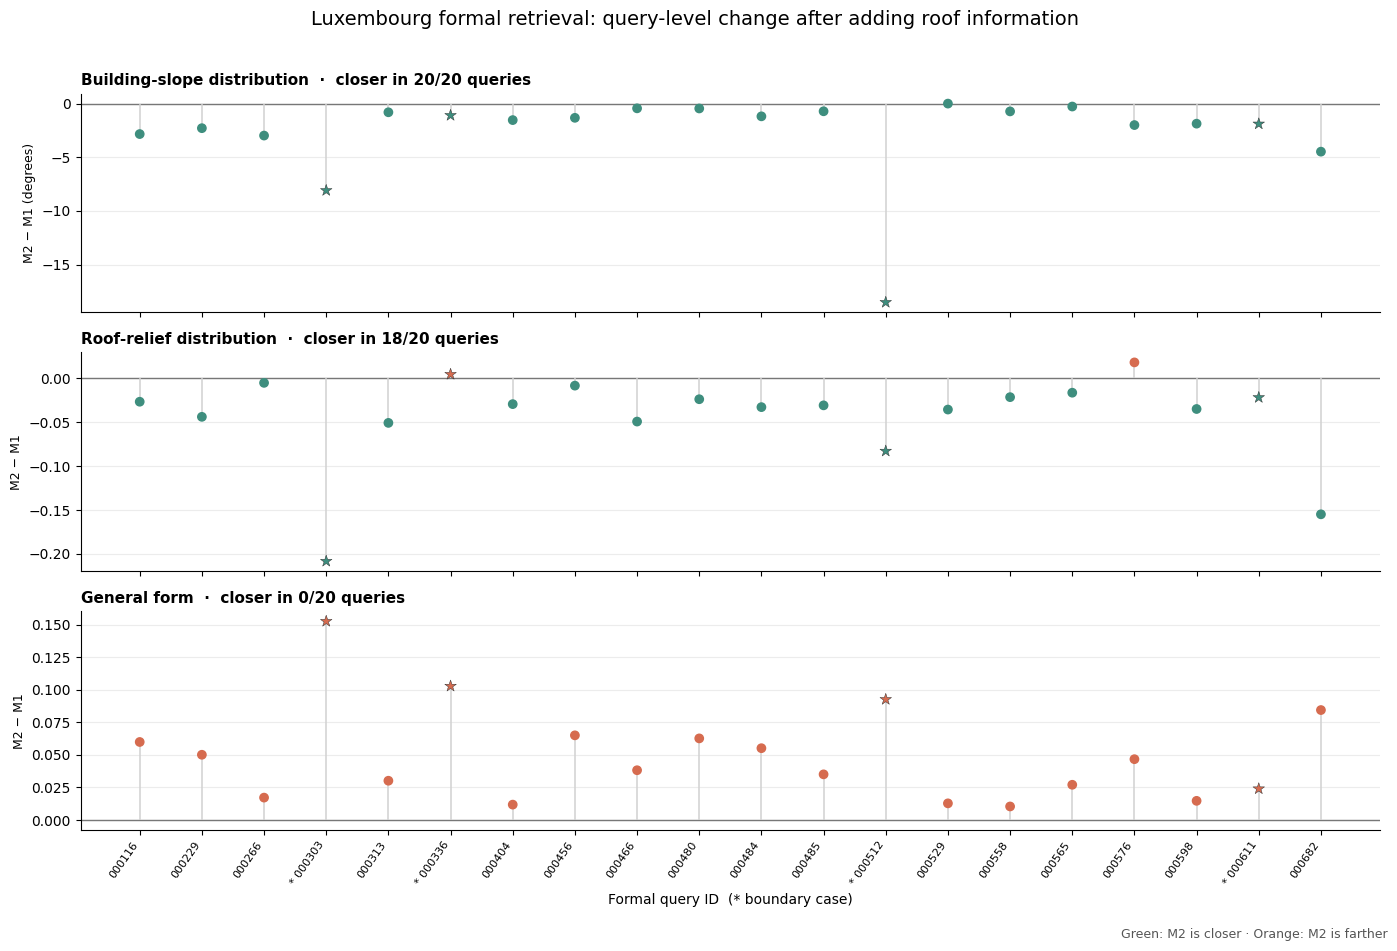

WindowsPath('E:/0_code/block-gml-casebase/casebase/lod2_roof_retrieval_experiment/outputs/formal_luxembourg/figures/formal_evaluation_overview.png')

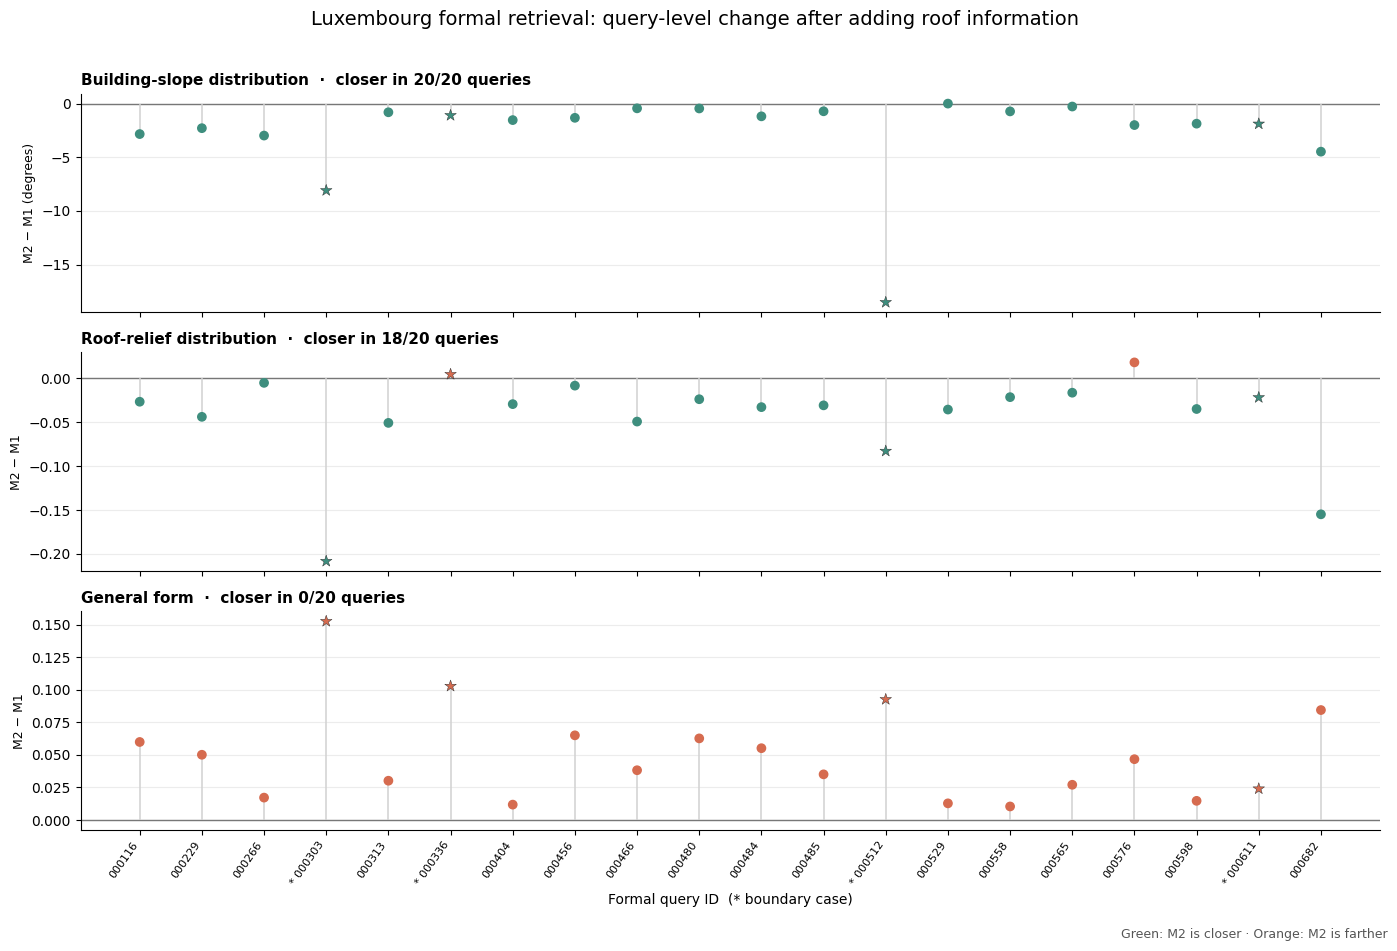

In [10]:
overview_path = FIGURE_DIR / 'formal_evaluation_overview.png'
overview_figure = make_formal_overview_figure(query_summary, overview_path)
display(overview_figure)
overview_path

### 8.2 一次性读取需要绘制的 LOD2 几何

先根据检索结果收集查询及候选街区 ID，再从原始 LOD2 表只读提取街区边界、建筑 footprint、屋顶面、墙面和地面。几何转换到 Luxembourg 的米制度量坐标系；本步骤不创建或修改数据库表。

In [11]:
comparison_plans = {
    query_id: build_comparison_plan(query_id, formal_results, top_k=TOP_K)
    for query_id in QUERY_IDS_TO_DRAW
}
scene_ids = sorted({
    panel.block_id
    for plan in comparison_plans.values()
    for panel in plan
})

connection = db.connect_from_env(HERE)
try:
    scenes = fetch_luxembourg_scenes(
        connection, scene_ids, metric_srid=int(config['metric_srid'])
    )
finally:
    connection.close()

assert set(scene_ids) == set(scenes)
print(f'已读取 {len(scenes)} 个唯一街区，准备绘制 {len(QUERY_IDS_TO_DRAW)} 张检索对照图。')

已读取 16 个唯一街区，准备绘制 2 张检索对照图。


### 8.3 批量保存 2D 平面与 3D 轴测对照图

Query 只在左侧绘制一次，右侧第一行为 M1 Top-5、第二行为 M2 Top-5。每个街区独立缩放并填满自身画框；2D 图突出街区边界与建筑 footprint，3D 图采用浅色街区底面、米白墙面、粉红屋顶和清晰边线。标题中的 `G`、`R` 分别为总体形态距离和屋顶距离。

In [12]:
image_records = []
for image_index, query_id in enumerate(QUERY_IDS_TO_DRAW, start=1):
    plan_path = FIGURE_DIR / f'{image_index:02d}_{query_id}_plan.png'
    axonometric_path = FIGURE_DIR / f'{image_index:02d}_{query_id}_axonometric.png'
    save_query_plan_comparison(
        query_id=query_id,
        retrieval=formal_results,
        scenes=scenes,
        output_path=plan_path,
        top_k=TOP_K,
    )
    save_query_axonometric_comparison(
        query_id=query_id,
        retrieval=formal_results,
        scenes=scenes,
        output_path=axonometric_path,
        top_k=TOP_K,
    )
    image_records.append({
        'query_id': query_id,
        'plan_path': str(plan_path),
        'axonometric_path': str(axonometric_path),
    })
    print(
        f'[{image_index:02d}/{len(QUERY_IDS_TO_DRAW):02d}] '
        f'{plan_path.name} + {axonometric_path.name}'
    )

image_index_table = pd.DataFrame(image_records)
image_index_table.to_csv(FIGURE_DIR / 'query_figure_index.csv', index=False)
display(image_index_table)

[01/02] 01_LU_LU_000303_plan.png + 01_LU_LU_000303_axonometric.png
[02/02] 02_LU_LU_000512_plan.png + 02_LU_LU_000512_axonometric.png


,query_id,plan_path,axonometric_path
0,LU_LU_000303,E:\0_code\block-gml-casebase\casebase\lod2_roo...,E:\0_code\block-gml-casebase\casebase\lod2_roo...
1,LU_LU_000512,E:\0_code\block-gml-casebase\casebase\lod2_roo...,E:\0_code\block-gml-casebase\casebase\lod2_roo...


## 9. 阅读结果时的边界

这一轮应回答的是：冻结后的 M2 是否在多数正式查询中缩短建筑级屋顶分布距离，以及相应的总体形态距离增加多少。三维图用于直观检查街区空间组织和屋顶构成的变化，但不能代替跨城市验证，也不应仅凭个别好看的案例证明方法有效。下一步需要在多个城市、数千至数万个有效街区上保持主方法不变，再制作跨城市汇总图和典型案例图。